In [2]:
from pathlib import Path
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

In [4]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")

# Fix the Ubuntu folder name if needed
train_df["image"] = train_df["image"].str.replace(
    "/raw/train/",
    "/raw/Train/",
    regex=False
)

print("Train:", len(train_df))
print("Validation:", len(val_df))

Train: 4263
Validation: 512


In [5]:
train_missing = sum(
    not Path(p).exists()
    for p in train_df["image"]
)

val_missing = sum(
    not Path(p).exists()
    for p in val_df["image"]
)

print("Missing train images:", train_missing)
print("Missing validation images:", val_missing)

Missing train images: 0
Missing validation images: 0


In [6]:
def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)
    image.set_shape((224, 224, 3))

    return image, label

In [8]:
def create_dataset(table, shuffle=False):
    paths = table["image"].tolist()
    labels = table["label"].tolist()

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)

    ds = ds.map(load_image)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)

print("Datasets ready!")

Datasets ready!


In [9]:
print("GPU:", tf.config.list_physical_devices("GPU"))

print(
    "MobileNetV2 saved:",
    Path("../models/best_mobilenetv2.keras").exists()
)

print(
    "ResNet50V2 saved:",
    Path("../models/best_resnet50v2.keras").exists()
)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
MobileNetV2 saved: True
ResNet50V2 saved: True


In [10]:
# MobileNetV2

model = tf.keras.models.load_model(
    "../models/best_mobilenetv2.keras"
)

base_model = model.get_layer("mobilenetv2_1.00_224")

print("MobileNetV2 loaded!")

MobileNetV2 loaded!


In [11]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers[-20:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Fine-tuning layers ready!")

Fine-tuning layers ready!


In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
mobile_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/finetuned_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

mobile_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [15]:
history_mobile = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        mobile_checkpoint,
        mobile_early_stopping
    ]
)

Epoch 1/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - accuracy: 0.9512 - loss: 0.1441 - val_accuracy: 0.8965 - val_loss: 0.2591
Epoch 2/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - accuracy: 0.9491 - loss: 0.1358 - val_accuracy: 0.9082 - val_loss: 0.2361
Epoch 3/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - accuracy: 0.9566 - loss: 0.1215 - val_accuracy: 0.8809 - val_loss: 0.2906
Epoch 4/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 13s 50ms/step - accuracy: 0.9608 - loss: 0.1141 - val_accuracy: 0.9102 - val_loss: 0.2180
Epoch 5/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.9606 - loss: 0.1057 - val_accuracy: 0.9160 - val_loss: 0.2321


In [16]:
# ResNet50V2

import gc

del model
del base_model

tf.keras.backend.clear_session()
gc.collect()

resnet_model = tf.keras.models.load_model(
    "../models/best_resnet50v2.keras"
)

resnet_base = resnet_model.get_layer("resnet50v2")

print("ResNet50V2 loaded!")

ResNet50V2 loaded!


In [17]:
print([layer.name for layer in resnet_model.layers])

['input_layer_16', 'sequential_3', 'rescaling_6', 'resnet50v2', 'global_average_pooling2d_6', 'dropout_6', 'dense_6']


In [18]:
resnet_base.trainable = True

for layer in resnet_base.layers[:-20]:
    layer.trainable = False

for layer in resnet_base.layers[-20:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("ResNet fine-tuning ready!")

ResNet fine-tuning ready!


In [19]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
resnet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/finetuned_resnet50v2.keras",
    monitor="val_loss",
    save_best_only=True
)

resnet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [21]:
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        resnet_checkpoint,
        resnet_early_stopping
    ]
)

Epoch 1/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 30s 81ms/step - accuracy: 0.9066 - loss: 0.2424 - val_accuracy: 0.9023 - val_loss: 0.2491
Epoch 2/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 19s 70ms/step - accuracy: 0.9303 - loss: 0.1963 - val_accuracy: 0.9453 - val_loss: 0.1544
Epoch 3/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.9472 - loss: 0.1492 - val_accuracy: 0.9355 - val_loss: 0.1743
Epoch 4/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 21s 78ms/step - accuracy: 0.9552 - loss: 0.1214 - val_accuracy: 0.9531 - val_loss: 0.1337
Epoch 5/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 29s 109ms/step - accuracy: 0.9681 - loss: 0.0919 - val_accuracy: 0.9590 - val_loss: 0.1367


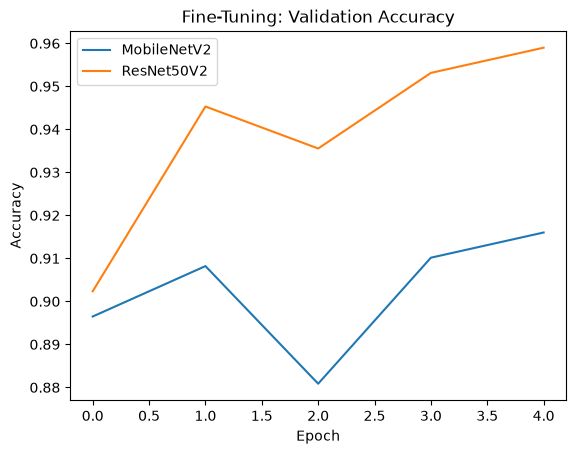

In [22]:
plt.plot(
    history_mobile.history["val_accuracy"],
    label="MobileNetV2"
)

plt.plot(
    history_resnet.history["val_accuracy"],
    label="ResNet50V2"
)

plt.title("Fine-Tuning: Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()